# Lava Blast (Harakim)

Lava Blast replaces Blast once the talent is learned (the `SK_BLAST` investment moves to
`SK_LAVA_BLAST`). The direct hit and the 75% splash are the same as Blast's, and like Blast the
cast always lands: there is no resist roll. Every target the hit gets through to also starts a
6 s Lava Burn.

**Rebalanced.** The burn was shortened from 15 s to 6 s (`LAVA_BURN_TICKS`, the same as the
recast interval). The landing roll was removed. It was `chance_base(skill, 12, Resist)` against the
primary target, and a miss cancelled the whole cast after the mana was spent. The "before" curves
below show the old behaviour.

| | |
|---|---|
| Class | Harakim |
| Target | Primary target + Blast's AoE splash (75% damage) |
| Cost | $\left(\lfloor\lfloor 3p'/2\rfloor/8\rfloor + 8\right)/3$ mana for player Harakim |
| Cooldown | 6 s exhaust (same as Blast) |
| Landing roll | none: always lands, like Blast |
| Duration | burn 6 s, one tick per second |
| Damage | direct `do_hurt(2p', 1)`; splash `do_hurt(⌊2p'/2⌋ + ⌊2p'/4⌋, 1)`; burn `max(1, ⌊max(1, ⌊3p'/4⌋)/2⌋)` HP/s, no armor |
| Source | `server/src/driver/skill/harakim.rs::skill_lava_blast`, `apply_lava_blast_dot`; tick in `server/src/state/stats.rs`; Blast in `driver/skill/blast.rs` |

---

# Formula

With $p$ the raw modified skill and $p' = \text{race}(\text{immunity}(p))$:

$$
\text{direct} = \tfrac{3}{4}\max(0,\ 2p' - \text{armor})
\qquad
\text{burn} = \max\!\left(1,\ \left\lfloor \tfrac{\max(1,\ \lfloor 3p'/4 \rfloor)}{2} \right\rfloor\right)\ \text{HP/s}
$$

$$
\text{sustained} = \frac{\text{direct} + 6 \cdot \text{burn}}{6\ \text{s}}
$$

The burn is applied only when the hit removes at least 1 HP, and it uses $p'$ without the
Element Switching bonus (which only multiplies the direct damage, ×1.2). The burn ticks at 1 s
through 6 s after the cast, so recasting on exhaust gets all 6 ticks out of each cast without
overlap. Before the change a recast replaced a running 15 s burn, so chain-casting wasted the
remaining 9 ticks.

| Quantity | Breakpoint |
|---|---|
| Burn at the raise caps | 39 HP/s at $p'$ 105 (234 HP over 6 s), 45 HP/s at 120 (270 HP) |
| Cost at the raise caps | 9 mana at 105 (Blast: 10), 10 at 120 (Blast: 11) |
| Landing roll | none (always lands, like Blast) |
| Ceiling | none: direct hit and burn grow linearly |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
EXHAUST_S = 6
BURN_S = 6
OLD_BURN_S = 15
ELEMENT_SWITCH_PCT = 20

# Model

In [2]:
def lava_cost(pp):
    return mm.idiv(mm.idiv(np.asarray(pp) * 3, 2) // 8 + 8, 3)


def blast_cost(pp):
    return mm.idiv(np.asarray(pp) * 2 // 8 + 5, 3)


def direct_hp(pp, armor=0, switched=False):
    dam = np.asarray(pp) * 2
    if switched:
        dam = dam * (100 + ELEMENT_SWITCH_PCT) // 100
    return mm.hurt_hp(dam, armor, kind=1)


def splash_hp(pp, armor=0):
    dam = np.asarray(pp) * 2
    return mm.hurt_hp(dam // 2 + dam // 4, armor, kind=1)


def burn_hps(pp):
    return mm.dot_tick(np.maximum(1, pp), "lava")


def lava_dps(p, armor=0, immun=0):
    """Recast on exhaust: every cast lands and its 6 s burn finishes before the next one."""
    pp = mm.spell_power(p, immun, "Harakim")
    hit = direct_hp(pp, armor)
    burn = np.where(hit > 0, burn_hps(pp), 0)
    return (hit + burn * BURN_S) / EXHAUST_S


def blast_dps(p, armor=0, immun=0):
    return direct_hp(mm.spell_power(p, immun, "Harakim"), armor) / EXHAUST_S


# Before the rebalance: 15 s burn, and the cast had to win a resist roll first.
def old_p_land(p, resist, pen_pct=0):
    return mm.p_chance_base(p, 12, mm.effective_resist(resist, pen_pct))


def old_burn_ticks_per_cast(q):
    """Expected burn ticks per 6 s window when recasting on exhaust with landing chance q.

    A landed cast restarts the 15 s burn, so a window gets 6 ticks if this cast or the previous one
    landed, and 3 (ticks 13-15) if only the cast two before landed."""
    q = np.asarray(q, dtype=float)
    return 6 * q + 6 * (1 - q) * q + 3 * (1 - q) ** 2 * q


def old_lava_dps(p, resist, armor=0, immun=0):
    pp = mm.spell_power(p, immun, "Harakim")
    q = old_p_land(p, resist)
    hit = direct_hp(pp, armor)
    burn = np.where(hit > 0, burn_hps(pp), 0)
    return (q * hit + burn * old_burn_ticks_per_cast(q)) / EXHAUST_S

# Validation

- `lava_blast_dot_records_caster_and_burns_for_6_seconds`: power 0 is stored as 1 and the item
  lasts `TICKS*6`.
- `compute_blast_damage_is_double_power_after_immunity`: skill 50 → (50, 100); with Immunity 40 →
  (30, 60). Lava Blast uses the same direct damage.
- `element_switching_boosts_changed_element_damage`: 100 → 100 on the same element, 120 after a
  switch.

In [3]:
assert burn_hps(0) == 1 and mm.TICKS * BURN_S == 216
assert mm.spell_power(50, 0, "Harakim") == 50 and mm.spell_power(50, 40, "Harakim") == 30
assert 50 * 2 == 100 and 30 * 2 == 60
assert 100 * (100 + ELEMENT_SWITCH_PCT) // 100 == 120
assert burn_hps(105) == 39 and burn_hps(120) == 45
assert lava_cost(105) == 9 and blast_cost(105) == 10 and lava_cost(120) == 10 and blast_cost(120) == 11
assert direct_hp(105) == 157.5 and splash_hp(105) == (105 + 52) * 0.75
assert lava_dps(105, armor=20) == 62.75 and blast_dps(105, armor=20) == 23.75
assert old_p_land(105, 70) == 0.95 and old_p_land(105, 158) == 0.0
assert old_burn_ticks_per_cast(1.0) == 6
print("Lava Blast model OK")

Lava Blast model OK


# Plots

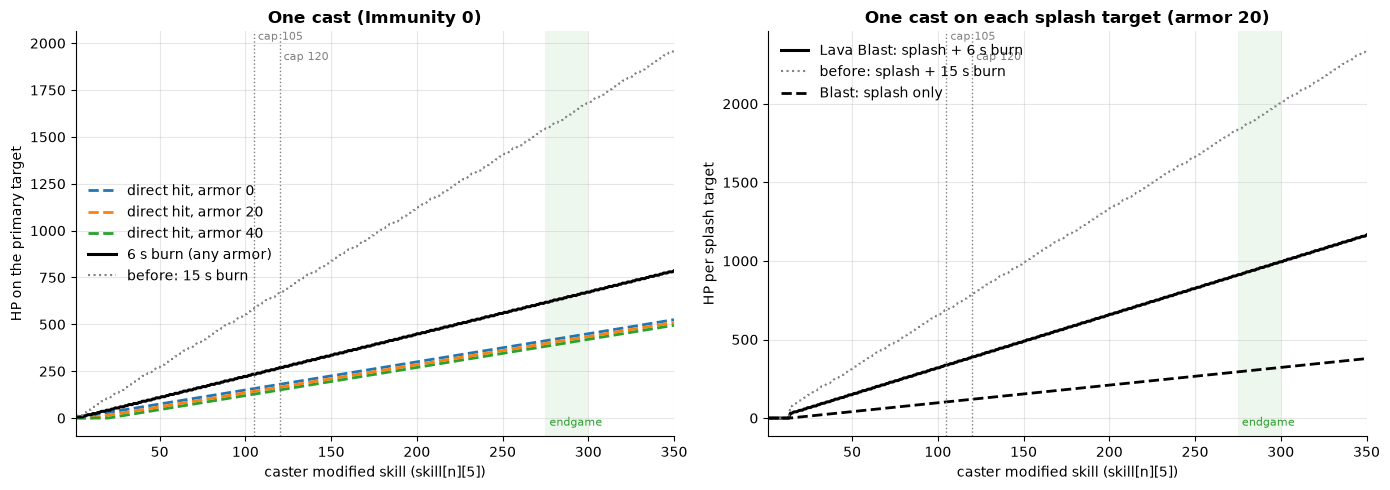

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in (0, 20, 40):
    ax.plot(P, direct_hp(P, armor), ls="--", label=f"direct hit, armor {armor}")
ax.plot(P, BURN_S * burn_hps(P), color="black", lw=2.2, label="6 s burn (any armor)")
ax.plot(P, OLD_BURN_S * burn_hps(P), color="grey", lw=1.5, ls=":", label="before: 15 s burn")
mm.skill_axis(ax, "HP on the primary target", "One cast (Immunity 0)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
splash = splash_hp(P, 20)
ax.plot(P, splash + np.where(splash > 0, BURN_S * burn_hps(P), 0), color="black", lw=2.2,
        label="Lava Blast: splash + 6 s burn")
ax.plot(P, splash + np.where(splash > 0, OLD_BURN_S * burn_hps(P), 0), color="grey", lw=1.5,
        ls=":", label="before: splash + 15 s burn")
ax.plot(P, splash, color="black", ls="--", label="Blast: splash only")
mm.skill_axis(ax, "HP per splash target", "One cast on each splash target (armor 20)")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

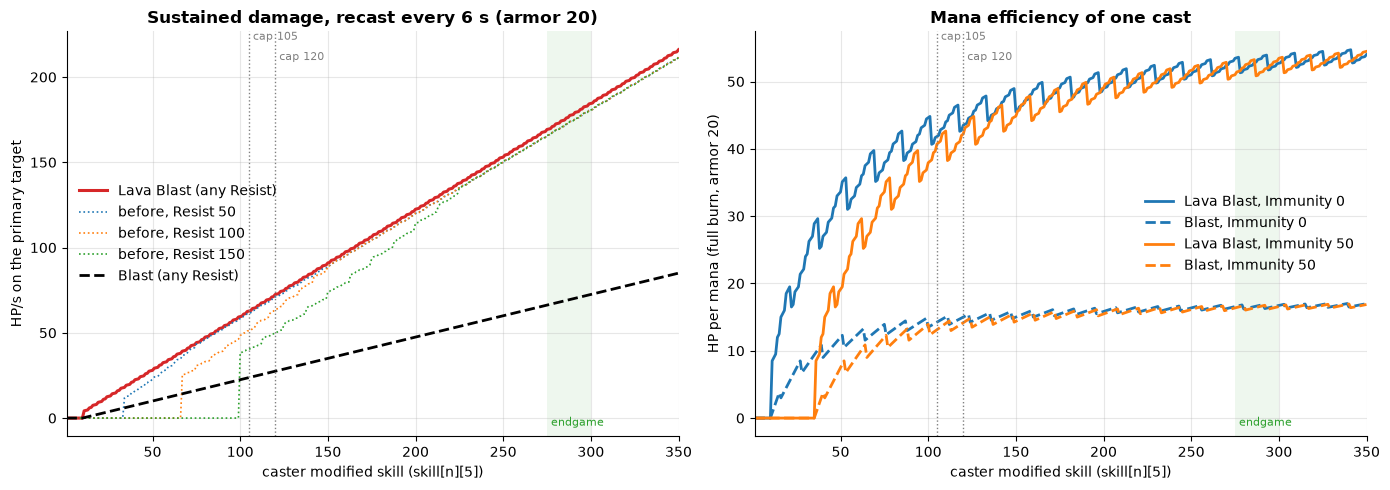

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(P, lava_dps(P, armor=20), color="tab:red", lw=2.2, label="Lava Blast (any Resist)")
for r in (50, 100, 150):
    ax.plot(P, old_lava_dps(P, r, armor=20), lw=1.2, ls=":", label=f"before, Resist {r}")
ax.plot(P, blast_dps(P, armor=20), color="black", ls="--", label="Blast (any Resist)")
mm.skill_axis(ax, "HP/s on the primary target", "Sustained damage, recast every 6 s (armor 20)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for imm, color in ((0, "tab:blue"), (50, "tab:orange")):
    pp = mm.spell_power(P, imm, "Harakim")
    hit = direct_hp(pp, 20)
    lava = hit + np.where(hit > 0, BURN_S * burn_hps(pp), 0)
    ax.plot(P, lava / lava_cost(pp), color=color, label=f"Lava Blast, Immunity {imm}")
    ax.plot(P, hit / blast_cost(pp), color=color, ls="--", label=f"Blast, Immunity {imm}")
mm.skill_axis(ax, "HP per mana (full burn, armor 20)", "Mana efficiency of one cast")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- The burn went from 15 s to 6 s and the resist roll was removed. Lava Blast now
  always lands, the same as Blast, and each burn ends just as the next cast comes off cooldown.
- At $p'$ 105 against armor 20, a cast deals 142.5 HP
  direct plus 234 HP of burn (376.5 HP). Before, it was 142.5 + 585 = 727.5 HP. A splash target
  now takes 102.75 + 234 = 336.75 HP instead of 687.75 HP. Casting once into a pack and leaving
  the burn to finish the job no longer works.
- Recasting already cut the old 15 s burn down to about 6 ticks,
  so chain-casting still realises about the same burn per cast. At skill 105 against armor 20,
  Lava Blast does 62.75 HP/s against any Resist. Before it did 61.5 / 51.2 / 40.5 HP/s against
  Resist 50 / 100 / 150. That is still 2.6× Blast's 23.75 HP/s. Against high Resist this is a
  buff: removing the roll matters more than the shorter burn.
- One cast deals 41.8 HP per mana at 105, down from 81. Blast deals
  14.25.
- `compute_blast_damage` looks for the Anguish-Lava
  marker, but `skill_lava_blast` computes its own damage and never does. Lava Blast replaces Blast,
  so a Harakim who takes both talents can never consume the marker (see `harakim_anguish_lava`).
- The doc comment on `cast_blast_effect` no longer says the function
  rolls the resist/sense chance.
- If 2.6× Blast is still too much while chain-casting, the remaining
  knob is the burn rate. `base/4` (19 HP/s at 105) would bring sustained damage to 42.75 HP/s,
  1.8× Blast. Separately, let Lava Blast consume the Anguish-Lava marker, or let the marker
  amplify the burn.